# BT4012 Fraud Analytics Group 14: RGCN

## Loading libraries

In [1]:
from pathlib import Path
import platform
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve, confusion_matrix
from sklearn.preprocessing import RobustScaler

## Configuration

In [2]:
ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
GRAPH_DIR = PROCESSED / "graph"
OUT_DIR = ROOT / "results"

DROP_RELATIONS = ["shared_related_org"]
KEEP_RELATIONS = ["related_party_transaction", "shared_related_unlisted_firm", "org_investor_and_related_party", "unlisted_investment_and_related_party"]
CLIP = None
RGCN_KW = dict(n_layers=2, skip=True)

HIDDEN = 64
DROPOUT = 0.3
LR = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300
PATIENCE = 30
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Hardware

In [3]:
torch.set_num_threads(8)

print(f"python {platform.python_version()} | torch {torch.__version__} | CUDA build {torch.version.cuda}")

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"running on {props.name}, {props.total_memory / 1e9:.1f} GB")
else:
    print("WARNING: CUDA not available, running on CPU")

python 3.12.5 | torch 2.7.1+cu126 | CUDA build 12.6
running on NVIDIA GeForce RTX 3070, 8.6 GB


# Graph Construction

One graph per year for each split. Nodes are the company-years of that year, edges are that year's
company - company links. Train on the train-year graphs, then predict on the test-year graph.

Node features (merged on `nodeID` + `Year`):
1. Tabular features (`tabular_features_folds/split_<s>`)
2. Text features and text embeddings (same for all splits)
3. TF-IDF (`text_tfidf/split_<s>`)
4. Degree features saved above

Moved from `graph.ipynb`. Needs `graph_preprocessing.ipynb` and the feature notebooks to have been run first. Saves `graphs_split_<s>.pt` and `feature_cols.csv`, which the sections below load.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
from torch_geometric.data import Data
from sklearn.preprocessing import RobustScaler

c:\Users\Timothy\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# fraud labels, used by the relation check below
df = pd.read_parquet("../data/processed/tabular_clean")

In [6]:
company_edges = pd.read_parquet("../data/processed/graph/company_edges.parquet")
degree_features = pd.read_csv("../data/processed/graph/degree_features.csv")
temporal_splits = pd.read_csv("../data/splits/temporal_splits.csv")
text_features = pd.read_parquet("../data/processed/text_features.parquet")
text_embeddings = pd.read_parquet("../data/processed/text_embeddings.parquet")

print("company_edges:  ", company_edges.shape)
print("degree_features:", degree_features.shape)
print("temporal_splits:", temporal_splits.shape)
print("text_features:  ", text_features.shape)
print("text_embeddings:", text_embeddings.shape)

company_edges:   (13157706, 4)
degree_features: (33634, 6)
temporal_splits: (105453, 5)
text_features:   (33664, 10)
text_embeddings: (33664, 66)


## Relation check
For each relation, the share of neighbours that are fraud, for fraud companies vs clean companies.
`lift` well above 1 means the relation is useful as an edge. Only 2014-2018 is used so no test year is looked at.

In [7]:
labels = df[["nodeID", "Year", "Label"]]

e = company_edges[company_edges["Year"] <= 2018]
e = e.merge(labels.rename(columns={"nodeID": "source_id", "Label": "source_label"}), on=["source_id", "Year"])
e = e.merge(labels.rename(columns={"nodeID": "target_id", "Label": "target_label"}), on=["target_id", "Year"])

relation_check = e.groupby(["relation", "source_label"])["target_label"].mean().unstack()
relation_check.columns = ["clean_company", "fraud_company"]
relation_check["lift"] = relation_check["fraud_company"] / relation_check["clean_company"]
relation_check.sort_values("lift", ascending=False).round(3)

,clean_company,fraud_company,lift
relation,,,
shared_related_unlisted_firm,0.037,0.072,1.934
related_party_transaction,0.042,0.073,1.759
org_investor_and_related_party,0.026,0.036,1.372
unlisted_investment_and_related_party,0.042,0.050,1.185
shared_auditor,0.048,0.052,1.099
shared_org_investor,0.037,0.041,1.096
shared_unlisted_investment,0.039,0.041,1.046
shared_individual_investor,0.055,0.057,1.033
shared_related_individual,0.053,0.051,0.969


## Choosing edges
All relations are kept except `shared_related_org` (51 links, no fraud company in 2014-2018).
Each relation is its own `edge_type` (0-11), so the RGCN learns a separate representation for each relation, and dense relations like `shared_auditor` are averaged on their own instead of drowning out the smaller ones.
The relation check above is kept for reference: it shows which relations are most linked to fraud.

In [8]:
drop_relations = ["shared_related_org"]   

graph_edges = company_edges[~company_edges["relation"].isin(drop_relations)].copy()
relation_list = sorted(graph_edges["relation"].unique())
relation_to_id = {r: i for i, r in enumerate(relation_list)}
graph_edges["edge_type"] = graph_edges["relation"].map(relation_to_id)

print(f"edges: {len(company_edges):,} -> {len(graph_edges):,}")
graph_edges.groupby(["edge_type", "relation"]).size()

edges: 13,157,706 -> 13,157,604


edge_type  relation                             
0          Investment                                141934
1          individual_investor_and_related_party      35128
2          org_investor_and_related_party              5468
3          related_party_transaction                  20890
4          shared_auditor                           8665326
5          shared_individual_investor                197878
6          shared_org_investor                       451376
7          shared_related_individual                 732956
8          shared_related_unlisted_firm               70146
9          shared_unlisted_investment               2757824
10         supply_chain_partner                        4716
11         unlisted_investment_and_related_party      73962
dtype: int64

## Node features for each split
Degree counts are log transformed, then scaled with a `RobustScaler` fitted on train rows only.

In [9]:
def get_node_features(s):
    rows = temporal_splits[temporal_splits["split"] == s]
    tabular = pd.read_parquet(f"../data/processed/tabular_features_folds/split_{s}")
    tfidf = pd.read_parquet(f"../data/processed/text_tfidf/split_{s}.parquet")

    features = rows.merge(tabular, on=["nodeID", "Year"], how="left")
    features = features.merge(text_features, on=["nodeID", "Year"], how="left")
    features = features.merge(text_embeddings, on=["nodeID", "Year"], how="left")
    features = features.merge(tfidf, on=["nodeID", "Year"], how="left")
    features = features.merge(degree_features, on=["nodeID", "Year"], how="left")

    # no row in degree_features means no edges
    deg_cols = ["n_Audit", "n_Investment", "n_Related-party transaction", "n_Supply chain"]
    features[deg_cols] = np.log1p(features[deg_cols].fillna(0))
    scaler = RobustScaler().fit(features.loc[features["role"] == "train", deg_cols])
    features[deg_cols] = scaler.transform(features[deg_cols])
    return features


features_0 = get_node_features(0)
feature_cols = [c for c in features_0.columns if c not in ["nodeID", "Year", "Label", "split", "role"]]
print("split 0 rows:", len(features_0))
print("features:", len(feature_cols))
print("missing values:", features_0[feature_cols].isna().sum().sum())

split 0 rows: 19494
features: 1414
missing values: 0


## Building the graph for each year

In [10]:
def build_graph(features, year):
    year_rows = features[features["Year"] == year].reset_index(drop=True)
    year_edges = graph_edges[graph_edges["Year"] == year]

    # nodeID -> row number in this year's graph
    node_index = {node: i for i, node in enumerate(year_rows["nodeID"])}
    src = year_edges["source_id"].map(node_index)
    dst = year_edges["target_id"].map(node_index)

    graph = Data(
        x=torch.tensor(year_rows[feature_cols].astype(float).values, dtype=torch.float),
        edge_index=torch.tensor(np.array([src.values, dst.values]), dtype=torch.long),
        edge_type=torch.tensor(year_edges["edge_type"].values, dtype=torch.long),
        y=torch.tensor(year_rows["Label"].values, dtype=torch.long),
    )
    graph.year = year
    graph.role = year_rows["role"].iloc[0]
    graph.node_ids = list(year_rows["nodeID"])
    return graph

In [11]:
all_graphs = {}
for s in range(4):
    features = get_node_features(s)
    all_graphs[s] = {}
    for year in sorted(features["Year"].unique()):
        all_graphs[s][int(year)] = build_graph(features, year)
    print(f"split {s}: graphs for {min(all_graphs[s])}-{max(all_graphs[s])}")

split 0: graphs for 2014-2019
split 1: graphs for 2014-2020
split 2: graphs for 2014-2021
split 3: graphs for 2014-2022


In [12]:
summary = []
for s, graphs in all_graphs.items():
    for year, g in graphs.items():
        summary.append({"split": s, "year": year, "role": g.role, "nodes": g.num_nodes,
                        "fraud": int(g.y.sum()), "edges": g.num_edges, "features": g.num_node_features})
pd.DataFrame(summary)

,split,year,role,nodes,fraud,edges,features
0,0,2014,train,2631,95,676824,1414
1,0,2015,train,2824,134,1563754,1414
2,0,2016,train,3125,173,1495632,1414
3,0,2017,train,3503,205,1273194,1414
4,0,2018,train,3596,225,1526722,1414
5,0,2019,test,3815,214,1266620,1414
6,1,2014,train,2631,95,676824,1414
7,1,2015,train,2824,134,1563754,1414
8,1,2016,train,3125,173,1495632,1414
9,1,2017,train,3503,205,1273194,1414


## Saving graph

In [13]:
for s, graphs in all_graphs.items():
    torch.save(graphs, f"../data/processed/graph/graphs_split_{s}.pt")
    print(f"saved graphs_split_{s}.pt")

pd.Series(feature_cols, name="feature").to_csv("../data/processed/graph/feature_cols.csv", index=False)
print("saved feature_cols.csv")

saved graphs_split_0.pt
saved graphs_split_1.pt
saved graphs_split_2.pt
saved graphs_split_3.pt
saved feature_cols.csv


## Splits, relations and feature blocks

In [14]:
splits = pd.read_csv(ROOT / "data" / "splits" / "temporal_splits.csv")
split_test_year = (splits[splits["role"] == "test"].groupby("split")["Year"].first().astype(int).to_dict())
TEST_YEARS = list(split_test_year.values())

all_relations = (pq.read_table(GRAPH_DIR / "company_edges.parquet", columns=["relation"]).column("relation").unique().to_pylist())
RELATIONS = sorted(r for r in all_relations if r not in DROP_RELATIONS)

feature_cols = pd.read_csv(GRAPH_DIR / "feature_cols.csv")["feature"].tolist()
text_cols = set()
for path in [PROCESSED / "text_features.parquet", PROCESSED / "text_embeddings.parquet", PROCESSED / "text_tfidf" / "split_0.parquet"]:
    text_cols |= set(pq.read_schema(path).names)
degree_cols = set(pd.read_csv(GRAPH_DIR / "degree_features.csv", nrows=0).columns)
BLOCK = np.array(["text" if c in text_cols else "degree" if c in degree_cols else "tabular" for c in feature_cols])
KEEP_RELATIONS = RELATIONS

print("test year per split:", split_test_year)
print(f"relations ({len(RELATIONS)}):", ", ".join(RELATIONS))
print(f"features ({len(feature_cols):,}):", pd.Series(BLOCK).value_counts().to_dict())

test year per split: {0: 2019, 1: 2020, 2: 2021, 3: 2022}
relations (12): Investment, individual_investor_and_related_party, org_investor_and_related_party, related_party_transaction, shared_auditor, shared_individual_investor, shared_org_investor, shared_related_individual, shared_related_unlisted_firm, shared_unlisted_investment, supply_chain_partner, unlisted_investment_and_related_party
features (1,414): {'tabular': 1238, 'text': 172, 'degree': 4}


## Data loading

In [15]:
def load_split(s: int):
    graphs = torch.load(GRAPH_DIR / f"graphs_split_{s}.pt", weights_only=False)
    xs, ids, years, labels, edge_index, edge_type = [], [], [], [], [], []
    offset = 0
    for yr in sorted(graphs):
        g = graphs[yr]
        xs.append(g.x)
        ids += list(g.node_ids)
        years.append(np.full(g.num_nodes, yr))
        labels.append(g.y.numpy())
        edge_index.append(g.edge_index + offset)
        edge_type.append(g.edge_type)
        offset += g.num_nodes

    nodes = pd.DataFrame({"nodeID": ids, "Year": np.concatenate(years), "Label": np.concatenate(labels)})
    X = torch.cat(xs).numpy()
    edge_index, edge_type = torch.cat(edge_index, dim=1), torch.cat(edge_type)

    expected = splits[splits["split"] == s]
    check = nodes.merge(expected, on=["nodeID", "Year"], how="left", suffixes=("", "_splits"))
    assert len(nodes) == len(expected), f"split {s}: node count differs from temporal_splits.csv"
    assert (check["Label"] == check["Label_splits"]).all(), f"split {s}: labels differ from temporal_splits.csv"
    assert nodes["Year"].max() == split_test_year[s], f"split {s}: last graph is not the test year"
    assert X.shape[1] == len(feature_cols), f"split {s}: feature count differs from feature_cols.csv"
    assert np.isfinite(X).all(), f"split {s}: features contain NaN or inf"
    assert int(edge_type.max()) < len(RELATIONS), "edge_type out of range; check DROP_RELATIONS"
    return nodes, X, edge_index, edge_type

def build_adjacency(edge_index, edge_type, n: int) -> list[torch.Tensor]:
    src, dst = edge_index
    adjs = []
    for r in range(len(RELATIONS)):
        m = edge_type == r
        i, j = dst[m], src[m]
        deg = torch.bincount(i, minlength=n).clamp(min=1).float()
        A = torch.sparse_coo_tensor(torch.stack([i, j]), 1.0 / deg[i], (n, n), check_invariants=False)
        adjs.append(A.coalesce().to(DEVICE))
    return adjs

def prepare_inputs(X: np.ndarray, fit_rows: np.ndarray) -> tuple[np.ndarray, dict]:
    X = X.copy()
    text = BLOCK == "text"
    X[:, text] = RobustScaler().fit(X[fit_rows][:, text]).transform(X[:, text])
    X = np.sign(X) * np.log1p(np.abs(X))

    clipped = {}
    if CLIP is not None:
        beyond = np.abs(X) > CLIP
        clipped = {b: float(beyond[:, BLOCK == b].mean()) for b in ("tabular", "text", "degree")}
        X = np.clip(X, -CLIP, CLIP)
    return X.astype(np.float32), clipped

def add_fraud_history(nodes: pd.DataFrame, X: np.ndarray) -> np.ndarray:
    """Append two columns: was this company fraud the year before (0 if not listed then),
    and was it listed the year before. Only labels from earlier years are used."""
    prev = (nodes[["nodeID", "Year", "Label"]]
            .assign(Year=nodes["Year"] + 1)
            .rename(columns={"Label": "prev_fraud"}))
    m = nodes[["nodeID", "Year"]].merge(prev, on=["nodeID", "Year"], how="left", validate="one_to_one")
    prev_fraud = m["prev_fraud"].fillna(0).to_numpy(np.float32)
    had_prev_year = m["prev_fraud"].notna().to_numpy(np.float32)
    return np.column_stack([X, prev_fraud, had_prev_year]).astype(np.float32)

## Model

In [16]:
class RGCNLayer(nn.Module):
    def __init__(self, d_in: int, d_out: int, n_rel: int):
        super().__init__()
        self.self_lin = nn.Linear(d_in, d_out)
        self.rel_lin = nn.ModuleList(nn.Linear(d_in, d_out, bias=False) for _ in range(n_rel))

    def forward(self, h, adjs):
        out = self.self_lin(h)
        for A, lin in zip(adjs, self.rel_lin):
            out = out + torch.sparse.mm(A, lin(h))
        return out

class RGCN(nn.Module):
    def __init__(self, d_in: int, n_rel: int, n_layers: int = 2, skip: bool = False):
        super().__init__()
        self.inp = nn.Linear(d_in, HIDDEN)
        self.convs = nn.ModuleList(RGCNLayer(HIDDEN, HIDDEN, n_rel) for _ in range(n_layers))
        self.skip = skip
        self.out = nn.Linear(HIDDEN * (n_layers + 1) if skip else HIDDEN, 1)
        self.drop = nn.Dropout(DROPOUT)

    def embed(self, x, adjs):
        h = self.drop(F.relu(self.inp(x)))
        hs = [h]
        for conv in self.convs:
            h = self.drop(F.relu(conv(h, adjs)))
            hs.append(h)
        return torch.cat(hs, dim=1) if self.skip else h

    def forward(self, x, adjs):
        return self.out(self.embed(x, adjs)).squeeze(1)

## Training

In [17]:
def scores(y, p):
    return roc_auc_score(y, p), average_precision_score(y, p)

def train_one(X, y, adjs, tr, va, n_rel, return_model=False, **model_kw):
    torch.manual_seed(SEED)
    model = RGCN(X.shape[1], n_rel, **model_kw).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    pos_weight = (y[tr] == 0).sum() / (y[tr] == 1).sum()
    y_np = y.cpu().numpy()
    
    history = []
    best_auc, best_state, best_epoch, waited = -1.0, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        opt.zero_grad()
        logits = model(X, adjs)
        loss = F.binary_cross_entropy_with_logits(logits[tr], y[tr], pos_weight=pos_weight)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = torch.sigmoid(model(X, adjs)).cpu().numpy()
        val_auc = roc_auc_score(y_np[va.cpu().numpy()], p[va.cpu().numpy()])
        history.append({"epoch": epoch, "loss": loss.item(), "val_auc": val_auc})
        if val_auc > best_auc:
            best_auc, best_epoch, waited = val_auc, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= PATIENCE:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(X, adjs)).cpu().numpy()
    hist = pd.DataFrame(history)
    return (p, best_auc, best_epoch, hist, model) if return_model else (p, best_auc, best_epoch, hist)

In [18]:
emb = {}
for s, test_year in split_test_year.items():
    val_year = test_year - 1
    nodes, X_np, edge_index, edge_type = load_split(s)
    year, labels = nodes["Year"].to_numpy(), nodes["Label"].to_numpy()
    X_np, _ = prepare_inputs(X_np, fit_rows=year < test_year)
    X_np = X_np[:, ~np.array([c.endswith(("_yoy", "_was_missing")) for c in feature_cols])]
    X_t = torch.tensor(add_fraud_history(nodes, X_np), device=DEVICE)
    adjs = build_adjacency(edge_index, edge_type, len(nodes))
    y_t = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    tr, va = (torch.tensor(m, device=DEVICE) for m in (year < val_year, year == val_year))

    p, val_auc, epoch, _, model = train_one(X_t, y_t, adjs, tr, va, len(adjs), return_model=True, **RGCN_KW)
    model.eval()
    with torch.no_grad():
        H = model.embed(X_t, adjs).cpu().numpy()

    emb[s] = {"H": H, "nodeID": nodes["nodeID"].to_numpy(), "year": year, "labels": labels, "p": p, "model": model}
    test = year == test_year
    print(f"split {s} ({test_year}): H {H.shape}, RGCN test AUC {roc_auc_score(labels[test], p[test]):.4f}")

    del X_t, y_t, adjs, tr, va  # free GPU memory before the next split
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

split 0 (2019): H (19494, 192), RGCN test AUC 0.8522
split 1 (2020): H (23763, 192), RGCN test AUC 0.8349
split 2 (2021): H (28532, 192), RGCN test AUC 0.8196
split 3 (2022): H (33664, 192), RGCN test AUC 0.8840


In [19]:
EMB_DIR = PROCESSED / "rgcn_embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)
for s, e in emb.items():
    val_year = split_test_year[s] - 1
    info = pd.DataFrame({"nodeID": e["nodeID"],
                         "Year": e["year"],
                         "Label": e["labels"],
                         "role": np.select([e["year"] < val_year, e["year"] == val_year], ["train", "val"], "test"),
                         "rgcn_score": e["p"]})
    vecs = pd.DataFrame(e["H"], columns=[f"h{i}" for i in range(e["H"].shape[1])])
    pd.concat([info, vecs], axis=1).to_parquet(EMB_DIR / f"split_{s}.parquet", index=False)
    print(f"saved split {s}: {len(info):,} rows, {e['H'].shape[1]} hidden columns")

saved split 0: 19,494 rows, 192 hidden columns
saved split 1: 23,763 rows, 192 hidden columns
saved split 2: 28,532 rows, 192 hidden columns
saved split 3: 33,664 rows, 192 hidden columns


## Walk-forward experiments

In [20]:
rows, preds, histories, split_info = [], [], [], []
for s, test_year in split_test_year.items():
    val_year = test_year - 1
    nodes, X, edge_index, edge_type = load_split(s)
    year = nodes["Year"].to_numpy()
    labels = nodes["Label"].to_numpy()
    test_mask = year == test_year

    X, clipped = prepare_inputs(X, fit_rows=year < test_year)
    X = X[:, ~np.array([c.endswith(("_yoy", "_was_missing")) for c in feature_cols])]
    X = add_fraud_history(nodes, X)
    adjs = build_adjacency(edge_index, edge_type, len(nodes))
    adjs = [adjs[RELATIONS.index(r)] for r in KEEP_RELATIONS]
    n_edges = sum(A._nnz() for A in adjs)
    X = torch.tensor(X, device=DEVICE)
    y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    tr, va = (torch.tensor(m, device=DEVICE) for m in (year < val_year, year == val_year))

    split_info.append({"split": s,
                       "test_year": test_year,
                       "nodes": len(nodes),
                       "edges": n_edges,
                       "features": X.shape[1],
                       "train_fraud": int(labels[year < val_year].sum()),
                       "val_fraud": int(labels[year == val_year].sum()),
                       "test_fraud": int(labels[test_mask].sum()),
                       **{f"clipped_{b}": v for b, v in clipped.items()}})
    print(f"split {s}: {len(nodes):,} nodes, {n_edges:,} edges, {X.shape[1]:,} features; "
          "values clipped: " + ", ".join(f"{b} {v:.2%}" for b, v in clipped.items()))

    p_by_model = {}
    for name, graph, kw in [("mlp", [], {}), ("rgcn", adjs, RGCN_KW)]:
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        p, val_auc, epoch, hist = train_one(X, y, graph, tr, va, len(graph), **kw)
        p_by_model[name] = p
        secs = time.perf_counter() - t0
        gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan

        auc, ap = scores(labels[test_mask], p[test_mask])
        rows.append({"model": name,
                     "split": s,
                     "test_year": test_year,
                     "best_epoch": epoch,
                     "val_auc": val_auc,
                     "test_auc": auc,
                     "test_pr_auc": ap,
                     "test_fraud_rate": labels[test_mask].mean(),
                     "seconds": secs,
                     "peak_gpu_gb": gpu_gb})
        preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model=name, score=p[test_mask]))
        histories.append(hist.assign(model=name, test_year=test_year))
        print(f"  {name:<5} {test_year}  epoch {epoch:>3}  val {val_auc:.4f}  "
              f"test AUC {auc:.4f}  PR-AUC {ap:.4f}  {secs:.0f}s  {gpu_gb:.2f} GB")

    # ensemble: the average of the MLP's and the RGCN's scores
    p = (p_by_model["mlp"] + p_by_model["rgcn"]) / 2
    val_mask = year == val_year
    auc, ap = scores(labels[test_mask], p[test_mask])
    rows.append({"model": "ens",
                 "split": s,
                 "test_year": test_year,
                 "best_epoch": np.nan,
                 "val_auc": roc_auc_score(labels[val_mask], p[val_mask]),
                 "test_auc": auc,
                 "test_pr_auc": ap,
                 "test_fraud_rate": labels[test_mask].mean(),
                 "seconds": np.nan,
                 "peak_gpu_gb": np.nan})
    preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model="ens", score=p[test_mask]))
    print(f"  {'ens':<5} {test_year}  test AUC {auc:.4f}  PR-AUC {ap:.4f}")
    del X, y, adjs, tr, va  # free GPU memory before the next split
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

res = pd.DataFrame(rows).round(4)
preds_df = pd.concat(preds, ignore_index=True)
hist_df = pd.concat(histories, ignore_index=True)
split_info = pd.DataFrame(split_info)
print()
print(res.groupby("model")[["test_auc", "test_pr_auc"]].mean())

OUT_DIR.mkdir(exist_ok=True)
res.to_csv(OUT_DIR / "rgcn_results.csv", index=False)
preds_df.to_csv(OUT_DIR / "rgcn_predictions.csv", index=False)
res

split 0: 19,494 nodes, 7,802,746 edges, 729 features; values clipped: 
  mlp   2019  epoch  82  val 0.8924  test AUC 0.8704  PR-AUC 0.3339  1s  0.28 GB
  rgcn  2019  epoch  64  val 0.8812  test AUC 0.8557  PR-AUC 0.3232  12s  0.58 GB
  ens   2019  test AUC 0.8749  PR-AUC 0.3616
split 1: 23,763 nodes, 9,345,718 edges, 729 features; values clipped: 
  mlp   2020  epoch 182  val 0.9147  test AUC 0.8393  PR-AUC 0.3590  1s  0.33 GB
  rgcn  2020  epoch  68  val 0.8938  test AUC 0.8217  PR-AUC 0.2986  14s  0.70 GB
  ens   2020  test AUC 0.8363  PR-AUC 0.3548
split 2: 28,532 nodes, 11,163,822 edges, 729 features; values clipped: 
  mlp   2021  epoch  53  val 0.8613  test AUC 0.8304  PR-AUC 0.3092  1s  0.39 GB
  rgcn  2021  epoch  74  val 0.8694  test AUC 0.8460  PR-AUC 0.3002  18s  0.87 GB
  ens   2021  test AUC 0.8487  PR-AUC 0.3273
split 3: 33,664 nodes, 13,157,604 edges, 729 features; values clipped: 
  mlp   2022  epoch 164  val 0.8868  test AUC 0.8952  PR-AUC 0.3605  2s  0.46 GB
  rgcn  2

,model,split,test_year,best_epoch,val_auc,test_auc,test_pr_auc,test_fraud_rate,seconds,peak_gpu_gb
0,mlp,0,2019,82.0,0.8924,0.8704,0.3339,0.0561,0.9357,0.2769
1,rgcn,0,2019,64.0,0.8812,0.8557,0.3232,0.0561,12.4489,0.5764
2,ens,0,2019,NaN,0.8937,0.8749,0.3616,0.0561,NaN,NaN
3,mlp,1,2020,182.0,0.9147,0.8393,0.3590,0.0485,1.4441,0.3285
4,rgcn,1,2020,68.0,0.8938,0.8217,0.2986,0.0485,14.3918,0.7049
5,ens,1,2020,NaN,0.9123,0.8363,0.3548,0.0485,NaN,NaN
6,mlp,2,2021,53.0,0.8613,0.8304,0.3092,0.0384,0.7810,0.3908
7,rgcn,2,2021,74.0,0.8694,0.8460,0.3002,0.0384,17.8197,0.8664
8,ens,2,2021,NaN,0.8722,0.8487,0.3273,0.0384,NaN,NaN
9,mlp,3,2022,164.0,0.8868,0.8952,0.3605,0.0240,1.5157,0.4562


### Split summary

In [21]:
split_info

,split,test_year,nodes,edges,features,train_fraud,val_fraud,test_fraud
0,0,2019,19494,7802746,729,607,225,214
1,1,2020,23763,9345718,729,832,214,207
2,2,2021,28532,11163822,729,1046,207,183
3,3,2022,33664,13157604,729,1253,183,123


## Visualising the metrics

In [22]:
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["mlp", "rgcn", "ens"]
TRAINED = ["mlp", "rgcn"] 
COLORS = {"mlp": "#2a78d6", "rgcn": "#eb6834", "ens": "#1baf7a"}
NAMES = {"mlp": "MLP (no graph)", "rgcn": "RGCN", "ens": "MLP + RGCN"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "lines.linewidth": 2,
    "font.size": 10,
    "axes.titlesize": 11,
    "legend.frameon": False,
})

def baseline(ax, x, y, label):
    ax.plot(x, y, ls="--", lw=1.2, color=MUTED, label=label)

def subset(model, yr):
    return preds_df[(preds_df["model"] == model) & (preds_df["Year"] == yr)]

### Headline metrics per test year

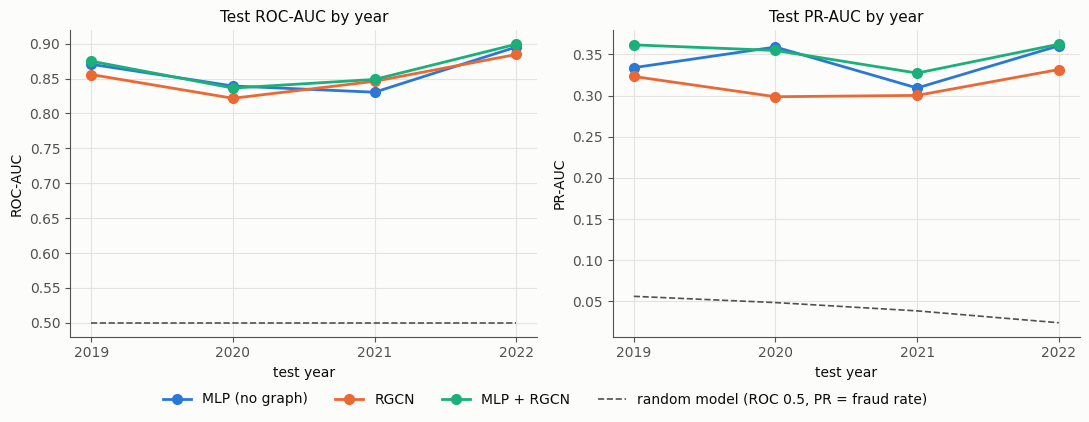

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rate = res[res["model"] == "mlp"].sort_values("test_year")
for ax, metric, title in [(axes[0], "test_auc", "ROC-AUC"), (axes[1], "test_pr_auc", "PR-AUC")]:
    for m in MODELS:
        d = res[res["model"] == m].sort_values("test_year")
        ax.plot(d["test_year"], d[metric], marker="o", ms=7, color=COLORS[m], label=NAMES[m])
    if metric == "test_auc":
        baseline(ax, rate["test_year"], [0.5] * len(rate), "random model")
    else:
        baseline(ax, rate["test_year"], rate["test_fraud_rate"], "random model")
    ax.set(title=f"Test {title} by year", xlabel="test year", ylabel=title, xticks=TEST_YEARS)
handles, names = axes[0].get_legend_handles_labels()
names[-1] = "random model (ROC 0.5, PR = fraud rate)"
fig.legend(handles, names, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(FIG_DIR / "metrics_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

### ROC and precision-recall curves

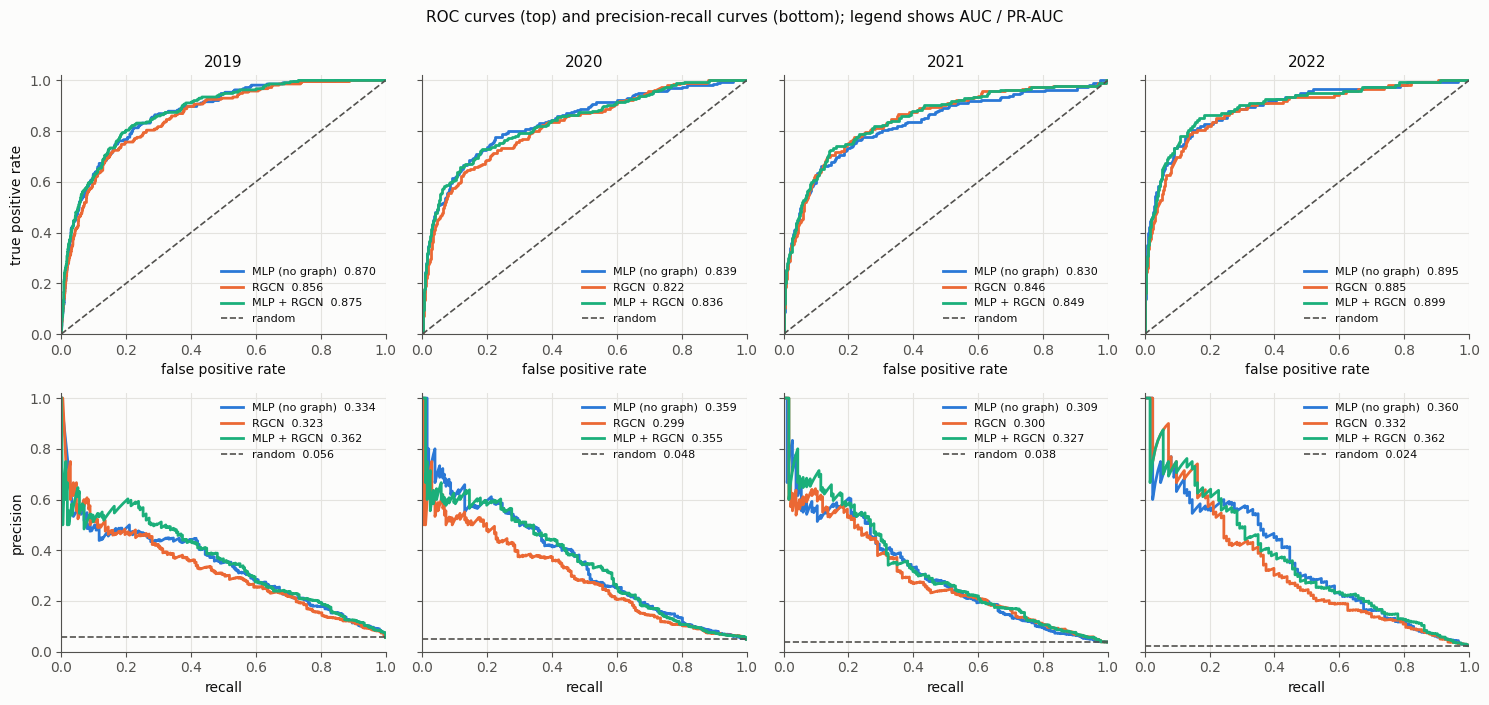

In [24]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 7), sharex=True, sharey="row")
for col, yr in enumerate(TEST_YEARS):
    roc_ax, pr_ax = axes[0, col], axes[1, col]
    for m in MODELS:
        g = subset(m, yr)
        fpr, tpr, _ = roc_curve(g["Label"], g["score"])
        prec, rec, _ = precision_recall_curve(g["Label"], g["score"])
        auc, ap = scores(g["Label"], g["score"])
        roc_ax.plot(fpr, tpr, color=COLORS[m], label=f"{NAMES[m]}  {auc:.3f}")
        pr_ax.plot(rec, prec, color=COLORS[m], label=f"{NAMES[m]}  {ap:.3f}")
    rate_yr = g["Label"].mean()
    baseline(roc_ax, [0, 1], [0, 1], "random")
    baseline(pr_ax, [0, 1], [rate_yr, rate_yr], f"random  {rate_yr:.3f}")
    roc_ax.set(title=str(yr), xlim=(0, 1), ylim=(0, 1.02), xlabel="false positive rate")
    roc_ax.xaxis.set_tick_params(labelbottom=True)
    pr_ax.set(xlabel="recall", ylim=(0, 1.02))
    roc_ax.legend(fontsize=8, loc="lower right")
    pr_ax.legend(fontsize=8, loc="upper right")
axes[0, 0].set_ylabel("true positive rate")
axes[1, 0].set_ylabel("precision")
fig.suptitle("ROC curves (top) and precision-recall curves (bottom); legend shows AUC / PR-AUC", y=1.0, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Frauds caught when reviewing the top-scored companies

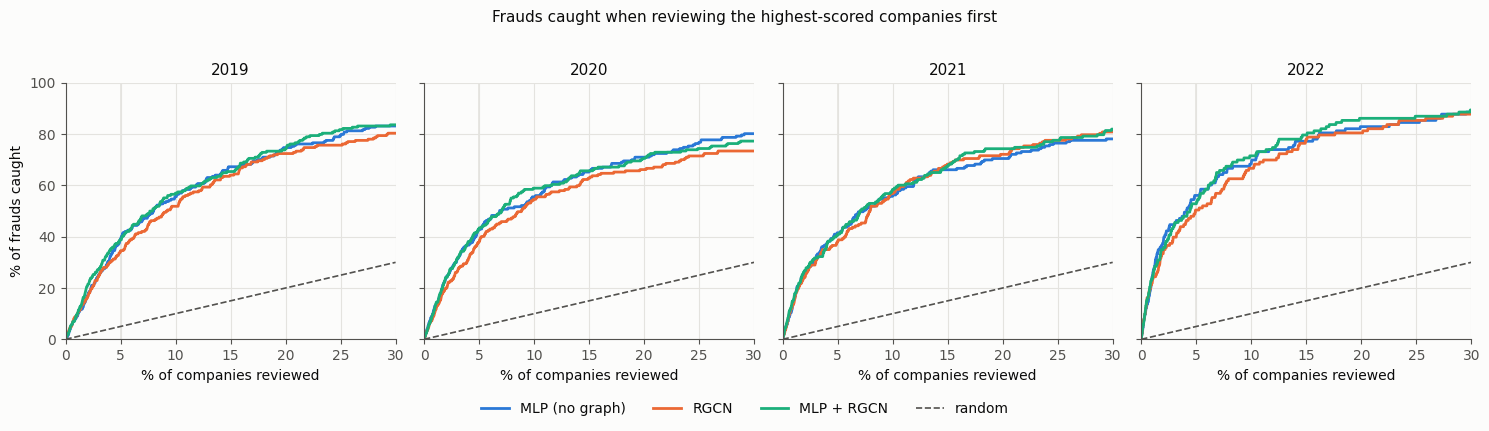

In [25]:
fig, axes = plt.subplots(1, len(TEST_YEARS), figsize=(15, 3.8), sharey=True)
for ax, yr in zip(axes, TEST_YEARS):
    for m in MODELS:
        y_sorted = subset(m, yr).sort_values("score", ascending=False)["Label"].to_numpy()
        reviewed = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
        ax.plot(reviewed * 100, np.cumsum(y_sorted) / y_sorted.sum() * 100, color=COLORS[m], label=NAMES[m])
    baseline(ax, [0, 30], [0, 30], "random")
    ax.axvline(5, color=GRID, lw=1.2, zorder=0)
    ax.set(title=str(yr), xlim=(0, 30), ylim=(0, 100), xlabel="% of companies reviewed")
axes[0].set_ylabel("% of frauds caught")
handles, names = axes[0].get_legend_handles_labels()
fig.suptitle("Frauds caught when reviewing the highest-scored companies first", y=1.02, fontsize=11)
fig.tight_layout()
fig.legend(handles, names, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.08))
fig.savefig(FIG_DIR / "capture_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Precision and recall at the top 1%, 5% and 10%

In [26]:
rows_k = []
for (m, yr), g in preds_df.groupby(["model", "Year"]):
    g = g.sort_values("score", ascending=False)
    for k in (0.01, 0.05, 0.10):
        top = g.head(int(np.ceil(k * len(g))))
        rows_k.append({"model": NAMES[m],
                       "test_year": yr,
                       "top_%_reviewed": int(k * 100),
                       "precision": top["Label"].mean(),
                       "recall": top["Label"].sum() / g["Label"].sum()})
topk = (pd.DataFrame(rows_k)
        .pivot_table(index=["top_%_reviewed", "test_year"], columns="model", values=["precision", "recall"])
        .round(3))
topk.to_csv(OUT_DIR / "topk_precision_recall.csv")
topk

precision                           recall  \
model                    MLP (no graph) MLP + RGCN   RGCN MLP (no graph)   
top_%_reviewed test_year                                                   
1              2019               0.487      0.538  0.513          0.089   
               2020               0.628      0.628  0.535          0.130   
               2021               0.583      0.604  0.542          0.153   
               2022               0.577      0.558  0.538          0.244   
5              2019               0.440      0.435  0.387          0.393   
               2020               0.416      0.421  0.369          0.430   
               2021               0.318      0.314  0.293          0.415   
               2022               0.268      0.253  0.241          0.561   
10             2019               0.312      0.319  0.291          0.556   
               2020               0.269      0.286  0.265          0.556   
               2021               0.216      0.224  0.218          0.563   
               2022               0.165      0.171  0.160          0.691   

                                            
model                    MLP + RGCN   RGCN  
top_%_reviewed test_year                    
1              2019           0.098  0.093  
               2020           0.130  0.111  
               2021           0.158  0.142  
               2022           0.236  0.228  
5              2019           0.388  0.346  
               2020           0.435  0.382  
               2021           0.410  0.383  
               2022           0.528  0.504  
10             2019           0.570  0.519  
               2020           0.589  0.546  
               2021           0.585  0.568  
               2022           0.715  0.667

### Training curves

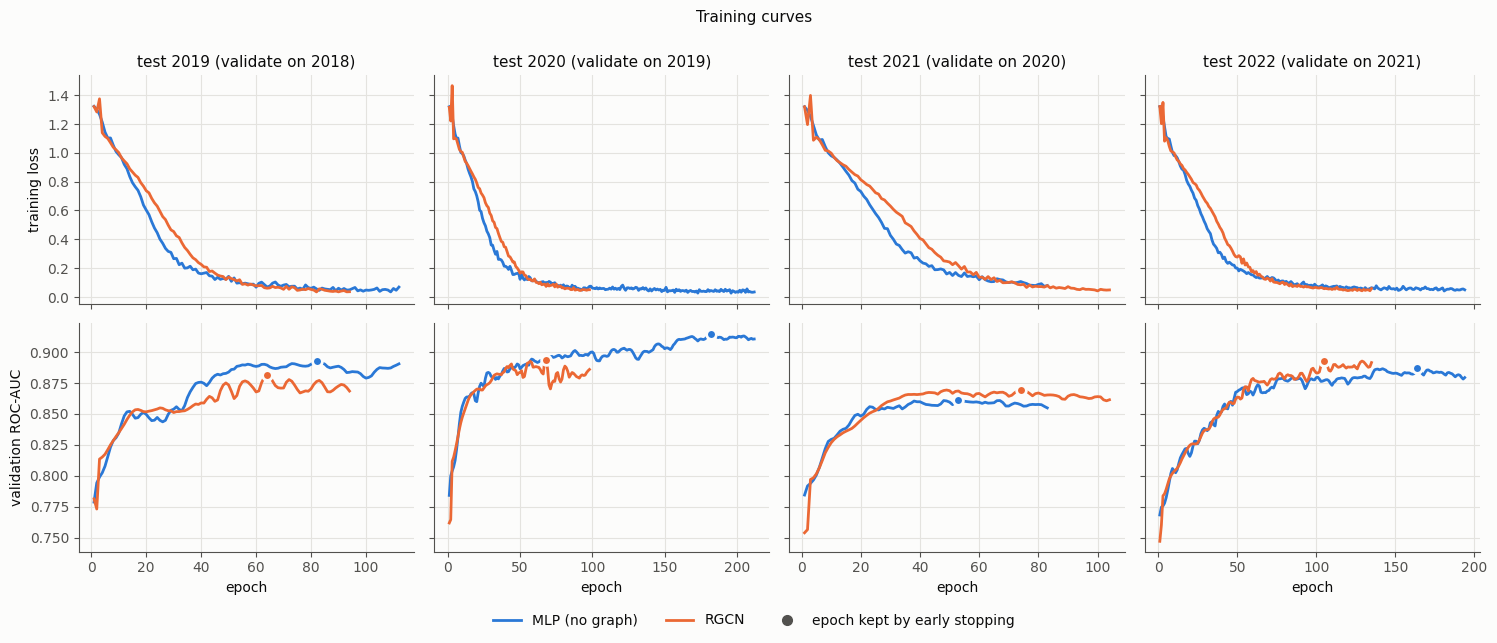

In [27]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 6), sharex="col", sharey="row")
for col, yr in enumerate(TEST_YEARS):
    for m in TRAINED:
        h = hist_df[(hist_df["model"] == m) & (hist_df["test_year"] == yr)]
        best = h.loc[h["val_auc"].idxmax()]
        axes[0, col].plot(h["epoch"], h["loss"], color=COLORS[m])
        axes[1, col].plot(h["epoch"], h["val_auc"], color=COLORS[m])
        axes[1, col].plot(best["epoch"], best["val_auc"], "o", ms=7, color=COLORS[m], markeredgecolor=SURFACE, markeredgewidth=2)
    axes[0, col].set_title(f"test {yr} (validate on {yr - 1})")
    axes[1, col].set_xlabel("epoch")
axes[0, 0].set_ylabel("training loss")
axes[1, 0].set_ylabel("validation ROC-AUC")

handles = [Line2D([], [], color=COLORS[m], label=NAMES[m]) for m in TRAINED]
handles.append(Line2D([], [], ls="", marker="o", ms=7, color=MUTED, label="epoch kept by early stopping"))
fig.suptitle("Training curves", y=1.0, fontsize=11)
fig.tight_layout()
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.05))
fig.savefig(FIG_DIR / "training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Confusion matrices

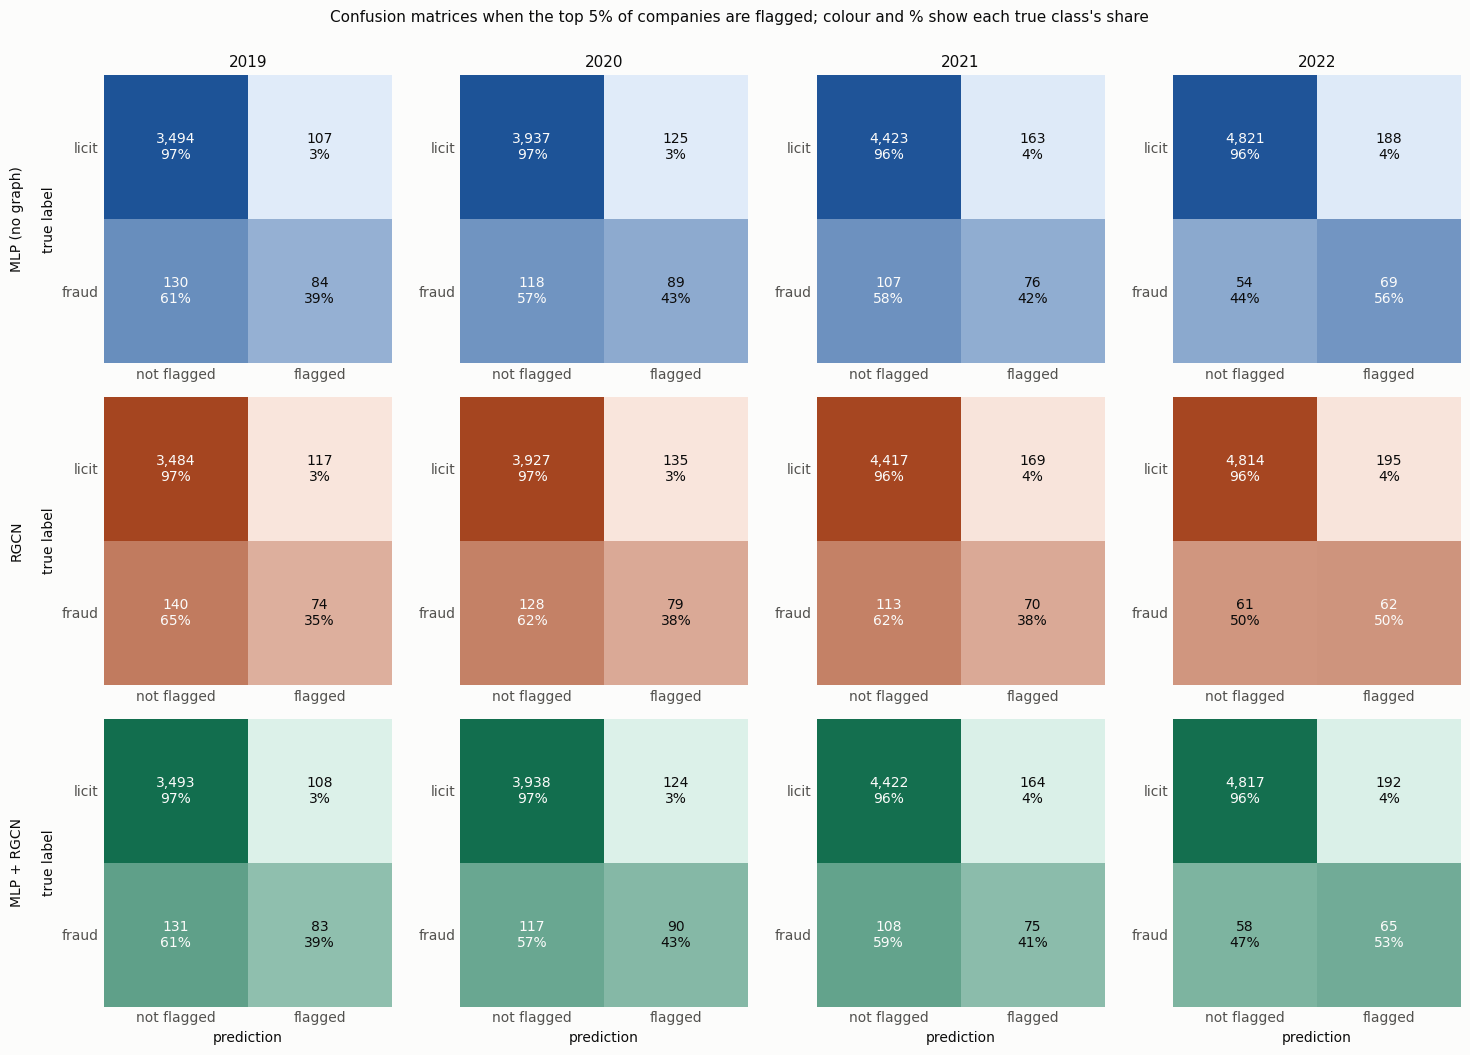

,model,test_year,TP,FP,FN,TN,precision,recall
0,MLP (no graph),2019,84,107,130,3494,0.440,0.393
1,MLP (no graph),2020,89,125,118,3937,0.416,0.430
2,MLP (no graph),2021,76,163,107,4423,0.318,0.415
3,MLP (no graph),2022,69,188,54,4821,0.268,0.561
4,RGCN,2019,74,117,140,3484,0.387,0.346
5,RGCN,2020,79,135,128,3927,0.369,0.382
6,RGCN,2021,70,169,113,4417,0.293,0.383
7,RGCN,2022,62,195,61,4814,0.241,0.504
8,MLP + RGCN,2019,83,108,131,3493,0.435,0.388
9,MLP + RGCN,2020,90,124,117,3938,0.421,0.435


In [28]:
FLAG_SHARE = 0.05
RAMPS = {"mlp": ["#e6f0fc", "#184f95"], "rgcn": ["#fcebe3", "#a3401a"], "ens": ["#e2f5ee", "#0d6b4a"]}

fig, axes = plt.subplots(len(MODELS), len(TEST_YEARS), figsize=(15, 3.5 * len(MODELS)))
cm_rows = []
for r, m in enumerate(MODELS):
    cmap = LinearSegmentedColormap.from_list(m, RAMPS[m])
    for c, yr in enumerate(TEST_YEARS):
        g = subset(m, yr)
        n_flag = int(np.ceil(FLAG_SHARE * len(g)))
        flagged = np.zeros(len(g), dtype=int)
        flagged[np.argsort(-g["score"].to_numpy())[:n_flag]] = 1
        cm = confusion_matrix(g["Label"], flagged, labels=[0, 1])
        share = cm / cm.sum(axis=1, keepdims=True)

        ax = axes[r, c]
        ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=10, color=SURFACE if share[i, j] > 0.5 else INK)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not flagged", "flagged"], yticklabels=["licit", "fraud"])
        ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.tick_params(length=0)
        if r == 0:
            ax.set_title(str(yr))
        if c == 0:
            ax.set_ylabel(f"{NAMES[m]}\n\ntrue label")
        if r == len(MODELS) - 1:
            ax.set_xlabel("prediction")

        tn, fp, fn, tp = cm.ravel()
        cm_rows.append({"model": NAMES[m],
                        "test_year": yr,
                        "TP": tp,
                        "FP": fp,
                        "FN": fn,
                        "TN": tn,
                        "precision": tp / (tp + fp),
                        "recall": tp / (tp + fn)})

fig.suptitle(f"Confusion matrices when the top {FLAG_SHARE:.0%} of companies are flagged; colour and % show each true class's share", y=1.0, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

cm_table = pd.DataFrame(cm_rows).round(3)
cm_table.to_csv(OUT_DIR / "confusion_matrices.csv", index=False)
cm_table